# NPFL129 Practicals - Perceptron, Logistic Regression, Grid Search

### Lab Objectives:
- Understand **linear separability** and how the Perceptron behaves when this condition is met vs. violated.
- Observe how the Perceptron can find a sub-optimal boundary that might generalize poorly to test data.
- Demonstrate the behavior on the **linearly unseparable** data and propose workarounds.
- Compare the behavior, loss minimization, and probabilistic outputs of **Logistic Regression** against the Perceptron.
- Show the motivation behind grid-search for hyperparameter tuning.

### Additional resources:
- [Perceptron algorithm visualization](https://vinizinho.net/projects/perceptron-viz/)

---
*Note: In this lab, we use the `scikit-learn` implementation of the algorithms. Hands-on implementation excercises are left for homework.

In [ ]:
# Required imports
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from sklearn.datasets import make_blobs, make_circles, make_moons
from sklearn.linear_model import Perceptron, LogisticRegression, SGDClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import ShuffleSplit, train_test_split
from sklearn.metrics import accuracy_score

---
## Part 1: The Perceptron & Linear Separability

### Example 1.1: Perfect Separation
Let's generate a synthetic 2D dataset that is perfectly linearly separable and see how the standard Perceptron performs.

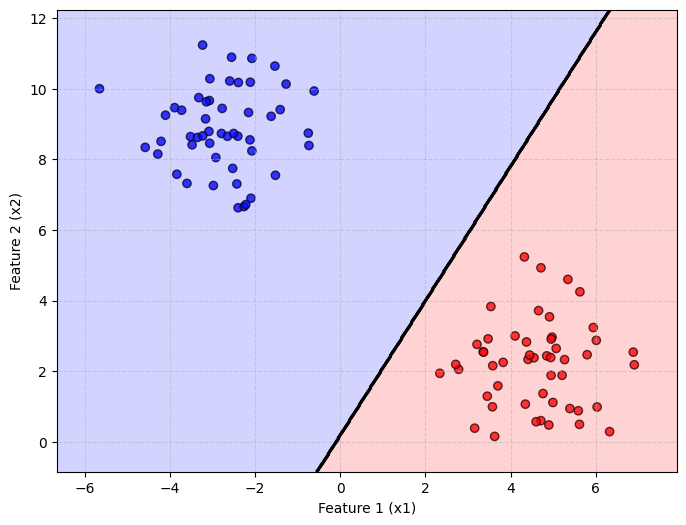

In [ ]:
def plot_decision_boundary(model, X, y, transform=None, show=True):
    """Helper function for plotting decision boundaries of our data."""
    if show:
        plt.figure(figsize=(8, 6))

    # Scatter plot of data points
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='bwr', edgecolors='k', alpha=0.8)

    # Create evenly spread grid datapoints given our the data (X)
    # We will use these to visualize the model's decision boundary (more points => more accurate)
    a_min, a_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    b_min, b_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xa, xb = np.meshgrid(np.linspace(a_min, a_max, 500), np.linspace(b_min, b_max, 500))

    grid = np.stack([xa.ravel(), xb.ravel()], axis=1)

    if transform:
        grid_transformed = transform.transform(grid)
        Z = model.predict(grid_transformed)
    else:
        Z = model.predict(grid)

    Z = Z.reshape(xa.shape)

    # Based on the predicted values on our grid, we can plot the decision boundary
    plt.contourf(xa, xb, Z, alpha=0.2, cmap='bwr')
    plt.contour(xa, xb, Z, colors='k', linewidths=1.5)

    plt.xlabel("Feature 1 (x1)")
    plt.ylabel("Feature 2 (x2)")
    plt.grid(True, linestyle='--', alpha=0.5)
    if show:
        plt.show()


# Generate perfectly separable data
X_train, y_train = make_blobs(n_samples=100, centers=2, n_features=2, random_state=42, cluster_std=1.2)

# Instantiate Perceptron
model = Perceptron()

# Model training
model.fit(X_train, y_train)

# Visualize the prediction on training data
plot_decision_boundary(model, X_train, y_train)

#### Thought Question:
Look closely at the decision boundary above. How close is it to the blue vs. red dots? What happens if our test data points are slightly perturbed?

### Example 1.2: The Perceptron's solution might not fit real data.
Let's generate a linearly separable dataset given the clusters mean and covariance to be able to display the clusters 95% confidence interval areas.

Perceptron returns any solution that **fits the training data** and may generalize poorly.

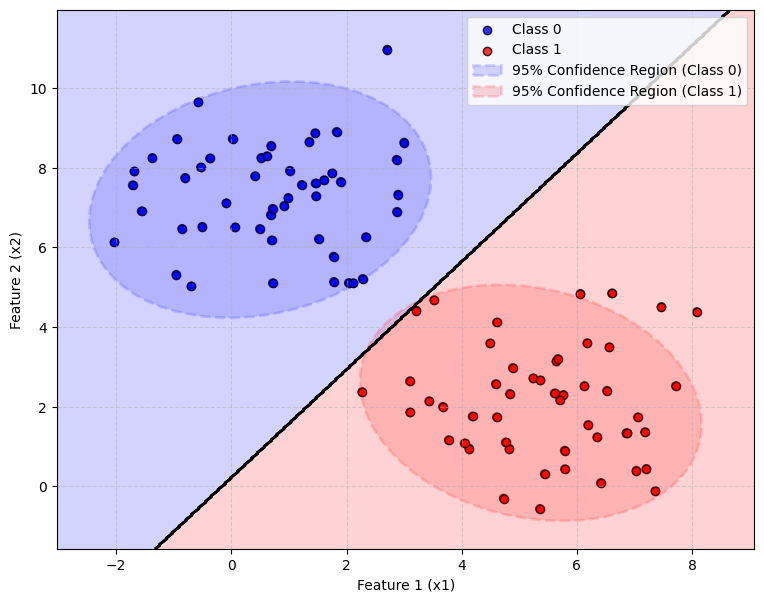

In [ ]:
def plot_decision_boundary_with_confidence(model, X, y, mean_0, cov_0, mean_1, cov_1, show=True):
    """Helper function for plotting decision boundary along with 95% confidence ellipses for both clusters."""
    # Prepare the figure and plot the core decision boundary structure first
    if show:
        plt.figure(figsize=(9, 7))
    plot_decision_boundary(model, X, y, transform=None, show=False)

    # Re-scatter to establish specific labeled classes for the legend
    plt.scatter(X[y==0, 0], X[y==0, 1], color='blue', edgecolors='k', alpha=0.8, label='Class 0')
    plt.scatter(X[y==1, 0], X[y==1, 1], color='red', edgecolors='k', alpha=0.8, label='Class 1')

    # Helper to draw 95% confidence ellipse
    def draw_ellipse(mean, cov, color, label):
        vals, vecs = np.linalg.eigh(cov)
        order = vals.argsort()[::-1]
        vals, vecs = vals[order], vecs[:, order]
        theta_deg = np.degrees(np.arctan2(*vecs[:, 0][::-1]))

        width, height = 2 * 2 * np.sqrt(vals)

        ellipse = Ellipse(xy=mean, width=width, height=height, angle=theta_deg,
                          edgecolor=color, facecolor=color, alpha=0.15, linestyle='--', linewidth=2, label=label)
        plt.gca().add_patch(ellipse)

    # Add the confidence intervals to the existing plot
    draw_ellipse(mean_0, cov_0, 'blue', '95% Confidence Region (Class 0)')
    draw_ellipse(mean_1, cov_1, 'red', '95% Confidence Region (Class 1)')

    plt.legend(loc='best')
    if show:
        plt.show()


def generate_two_gaussian_clusters():
    """Generate two distributions where the 95% confidence regions almost touch but do not overlap."""
    np.random.seed(42)
    n_samples = 100
    half_samples = n_samples // 2

    # Adjust means further apart so that the 95% confidence ellipses almost touch
    m_0 = np.array([0.5, 7.2])
    c_0 = np.array([[2.2, 0.4], [0.4, 2.2]])

    m_1 = np.array([5.2, 2.1])
    c_1 = np.array([[2.2, -0.4], [-0.4, 2.2]])

    # Sample points
    X_0 = np.random.multivariate_normal(m_0, c_0, half_samples)
    X_1 = np.random.multivariate_normal(m_1, c_1, half_samples)

    X = np.vstack([X_0, X_1])
    y = np.array([0] * half_samples + [1] * half_samples)

    return X, y, m_0, c_0, m_1, c_1

X_train, y_train, mean_0, cov_0, mean_1, cov_1 = generate_two_gaussian_clusters()

# TODO: Instantiate and train Perceptron
model = Perceptron(random_state=42)
model.fit(X_train, y_train)

# Visualize with 95% confidence intervals
plot_decision_boundary_with_confidence(model, X_train, y_train, mean_0, cov_0, mean_1, cov_1)

#### Solution 1.2.1:
Augment our data with additional points that move the boundary in the desired direction.

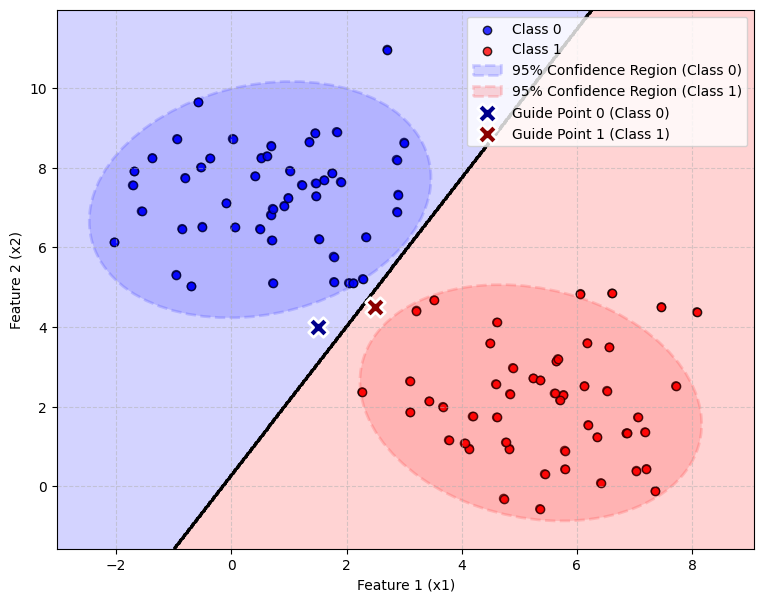

In [ ]:
def plot_decision_boundary_with_confidence_and_guides(model, X, y, mean_0, cov_0, mean_1, cov_1, g0, g1):
    """Plots decision boundary with confidence ellipses, then adds visual indicators for guide points."""
    # Call the existing function to plot boundaries and confidence region.
    plt.figure(figsize=(9, 7))
    plot_decision_boundary_with_confidence(model, X, y, mean_0, cov_0, mean_1, cov_1, show=False)

    # Overlay the guides on the active plot
    plt.scatter(g0[:, 0], g0[:, 1], color='darkblue', marker='X', s=200, edgecolor='white', linewidth=2, label='Guide Point 0 (Class 0)', zorder=5)
    plt.scatter(g1[:, 0], g1[:, 1], color='darkred', marker='X', s=200, edgecolor='white', linewidth=2, label='Guide Point 1 (Class 1)', zorder=5)

    # Update legend to include the new guides
    plt.legend(loc='best')
    plt.show()

# In practice, we can use

# Create artificial guide points near the boundary to force a wider margin
guide_0 = np.array([[1.5, 4.0]]) # Pushes class 0 boundary up
guide_1 = np.array([[2.5, 4.5]]) # Pushes class 1 boundary down

# Augment training data
X_train_augmented = np.vstack([X_train, guide_0, guide_1])
y_train_augmented = np.hstack([y_train, [0], [1]])

# Train a standard Perceptron on the augmented data
reg_perceptron = Perceptron(random_state=42)
reg_perceptron.fit(X_train_augmented, y_train_augmented)

# Visualize with confidence intervals and guide points
plot_decision_boundary_with_confidence_and_guides(reg_perceptron, X_train, y_train, mean_0, cov_0, mean_1, cov_1, guide_0, guide_1)

Solution 1.2.2:
Use a regularized perceptron (l2-regularization).

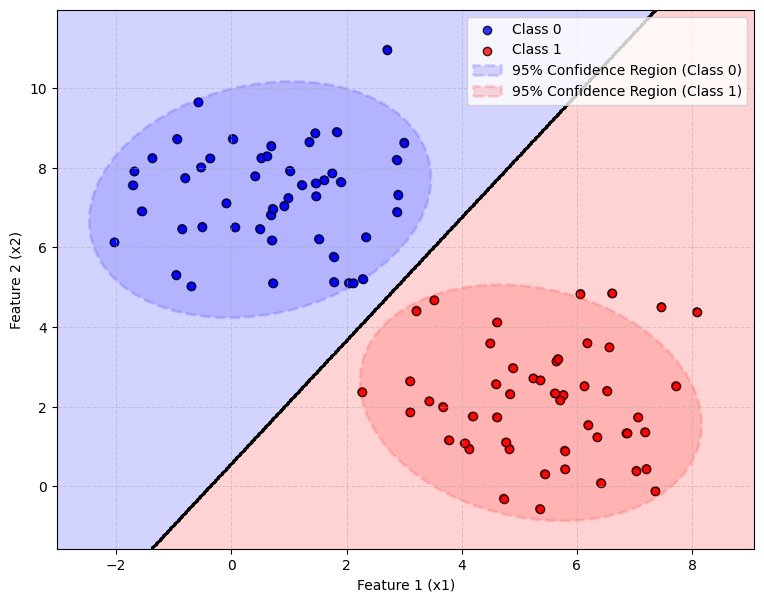

In [ ]:
# Instantiate and train an l2-regularized Perceptron
model = Perceptron(penalty='l2', alpha=0.005, random_state=42)
model.fit(X_train, y_train)

# Visualize the decision boundary along with confidence intervals
plot_decision_boundary_with_confidence(model, X_train, y_train, mean_0, cov_0, mean_1, cov_1)

### Example 1.3: Perceptron Limitations

Let's see what happens during training if our data is not linearly separable.

Question: How can we transform the data to make them linearly separable?

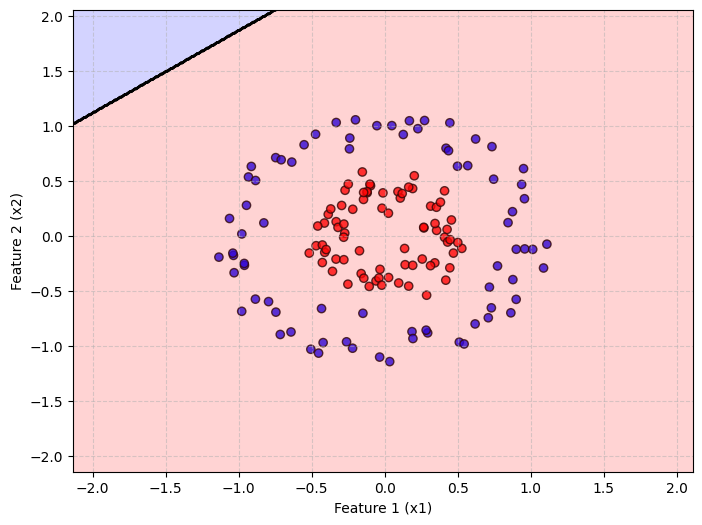

In [ ]:
# Generate non-linearly separable (concentric circles) data
X_train, y_train = make_circles(n_samples=150, noise=0.1, factor=0.4, random_state=12)

# To demonstrate a 'failed/cycled' state, we restrict max_iter to a tiny number and turn off early stopping
model = Perceptron(max_iter=100, tol=None, shuffle=False, random_state=1)
model.fit(X_train, y_train)

# Visualize the failed/cycled training boundary
plot_decision_boundary(model, X_train, y_train)

#### The Solution: Adding a new feature (e.g. distance from center)
We can fix this by replacing one of the original features with a new feature to the training data (distance form the data point cluster centroid.

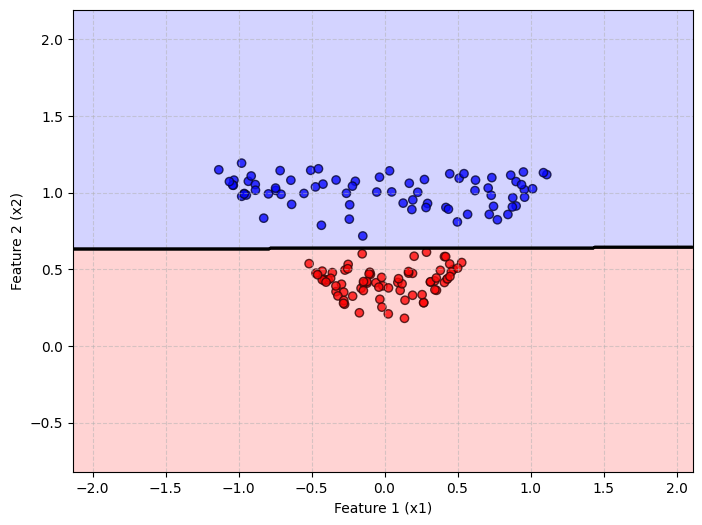

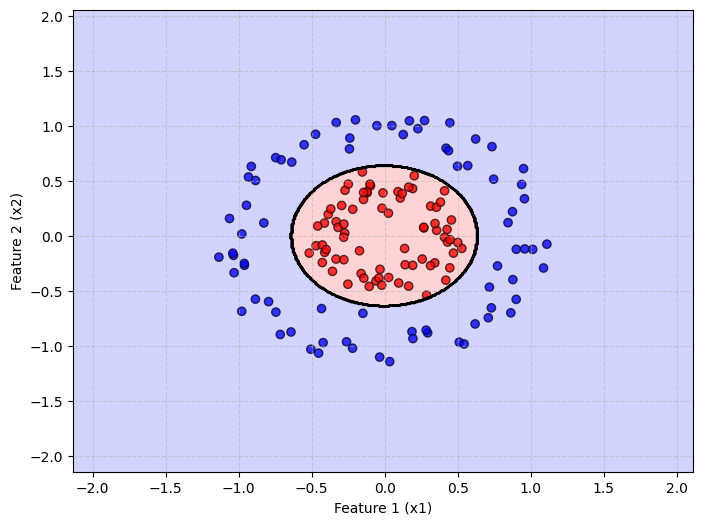

In [ ]:
# Create a transformer class to apply the same replacement to grid points for plotting
class DistanceToCentroidTransform:
    """A transform class to replace the second feature with the origina data point distance from the cluster centroid."""
    def __init__(self, centroid):
        self.centroid = centroid
    def transform(self, grid):
        distances = np.linalg.norm(grid - self.centroid, axis=1).reshape(-1, 1)
        return np.hstack([grid[:, 0:1], distances])

# Transform the input data
transformer = DistanceToCentroidTransform(np.mean(X_train, axis=0))
X_train_transformed = transformer.transform(X_train)

# TODO: Instantiate a new Perceptron and train it on this feature space
model = Perceptron(max_iter=100, tol=1e-3, shuffle=False, random_state=1)
model.fit(X_train_transformed, y_train)

# Plot the resulting boundary with respect to the transformed space...
plot_decision_boundary(model, X_train_transformed, y_train)

# ... and the resulting boundary mapped back to our original 2D space
plot_decision_boundary(model, X_train, y_train, transform=transformer)

Exercise: Other transformations

- Try out other transformations

- Instead of replacing the x2 with the "distance" feature. Try adding the distance as an additional x3 feature or replace both original features with the distance.

(You might need to adjust the `plot_decision_boundary` if you change your feature space form 2D to other dimensionality.)

---
## Part 2: Logistic Regression Comparison

### Example 2.1: Probabilities & Calibration
The Perceptron can only output hard labels ($0$ or $1$). Logistic Regression models probabilities ($P(y=1|x)$), giving you a metric of confidence.

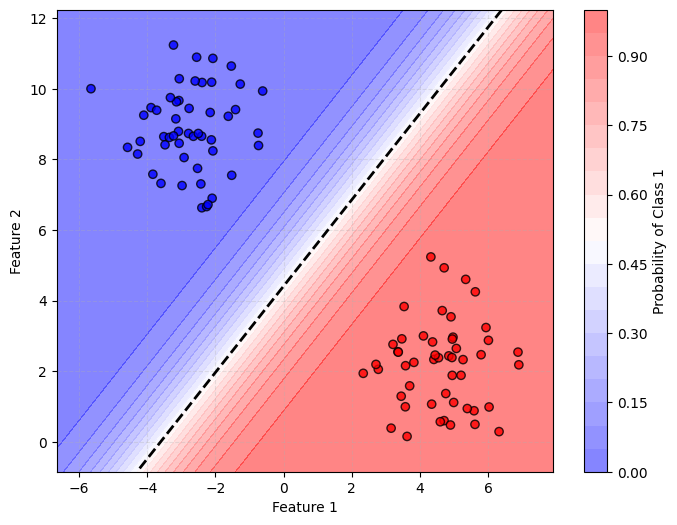

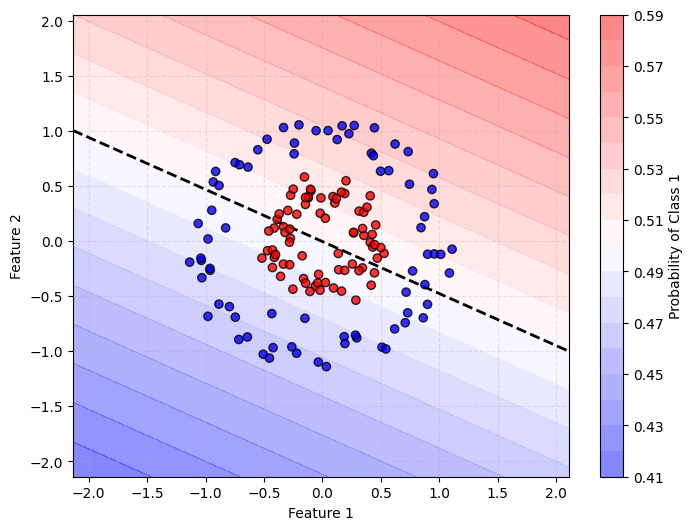

In [ ]:
def plot_probability_contours(model, X, y):
    plt.figure(figsize=(8, 6))

    # Plot data points
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='bwr', edgecolors='k', alpha=0.8, zorder=3)

    # Generate a grid
    a_min, a_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    b_min, b_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xa, xb = np.meshgrid(np.linspace(a_min, a_max, 500), np.linspace(b_min, b_max, 500))
    grid = np.stack([xa.ravel(), xb.ravel()], axis=1)

    # Predict class 1 probabilities
    probs = model.predict_proba(grid)[:, 1]
    probs_grid = probs.reshape(xa.shape)

    # Draw shaded probability contours representing confidence
    contour = plt.contourf(xa, xb, probs_grid, levels=20, cmap='bwr', alpha=0.5)
    plt.colorbar(contour, label='Probability of Class 1')

    # Draw the decision boundary (P = 0.5)
    plt.contour(xa, xb, probs_grid, levels=[0.5], colors='black', linewidths=2.0, linestyles='--')

    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.show()


# Train logistic regression on the linearly separable data
X_train, y_train = make_blobs(n_samples=100, centers=2, n_features=2, random_state=42, cluster_std=1.2)
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)
plot_probability_contours(model, X_train, y_train)

# Train on the circle-centered data
X_train, y_train = make_circles(n_samples=150, noise=0.1, factor=0.4, random_state=12)
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)
plot_probability_contours(model, X_train, y_train)

### Example 2.2: Analyzing the features
Model coeficients (weights) can give us better insight on the impact of individual features on the prediction outcome.

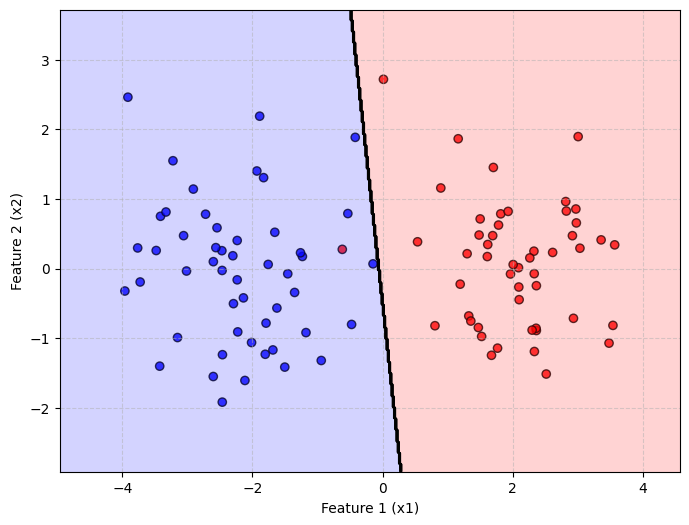

=== Logistic Regression Clear Feature Analysis ===
Intercept (Bias): 0.1317
Feature 1 Coefficient: 2.2852 (Very strong impact)
Feature 2 Coefficient: 0.2666 (Weak/negligible impact)


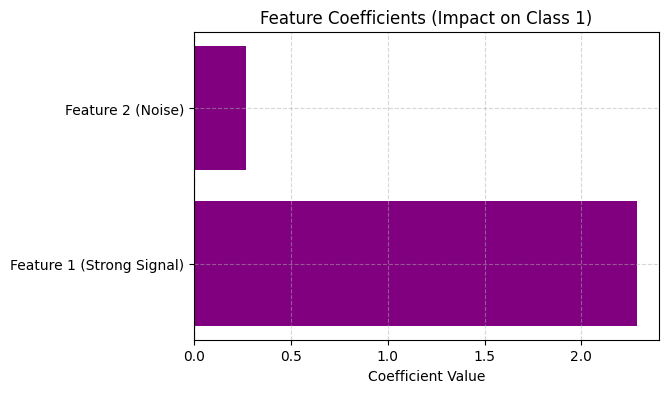

In [ ]:
def plot_feature_coefficients(features, coefficients):
    """Plots the feature coefficients of a trained linear model."""
    plt.figure(figsize=(6, 4))
    plt.barh(features, coefficients, color='purple')
    plt.axvline(x=0, color='black', linestyle='--')
    plt.title("Feature Coefficients (Impact on Class 1)")
    plt.xlabel("Coefficient Value")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

# Let's create an engineered dataset where:
# Feature 1 is highly predictive of the target.
# Feature 2 is mostly random noise (non-predictive).
np.random.seed(42)
X_1 = np.concatenate([np.random.normal(loc=-2, scale=1.0, size=50), np.random.normal(loc=2, scale=1.0, size=50)])
X_2 = np.random.normal(loc=0, scale=1.0, size=100) # Noise

X_train = np.stack([X_1, X_2], axis=1)
y_train = np.array([0]*50 + [1]*50)

# Train Logistic Regression
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

# Get weights and intercept
coefficients = model.coef_[0]
intercept = model.intercept_[0]

# Plot the decision boundary
plot_decision_boundary(model, X_train, y_train)

print("=== Logistic Regression Clear Feature Analysis ===")
print(f"Intercept (Bias): {intercept:.4f}")
for i, coef in enumerate(coefficients):
    print(f"Feature {i+1} Coefficient: {coef:.4f} (Very strong impact)" if abs(coef) > 1.0 else f"Feature {i+1} Coefficient: {coef:.4f} (Weak/negligible impact)")

# Visualize the stark difference using the isolated function
features = ['Feature 1 (Strong Signal)', 'Feature 2 (Noise)']
plot_feature_coefficients(features, coefficients)

Example 2.3: Analyzing the features (beware of multilinearity)

Even when the individual features do not correlate with the target label distribution, their combination can correlate well.




=== Individual Feature Correlations ===
Correlation of Feature 1 with Label: -0.0815 (Nearly zero)
Correlation of Feature 2 with Label: -0.0237 (Nearly zero)


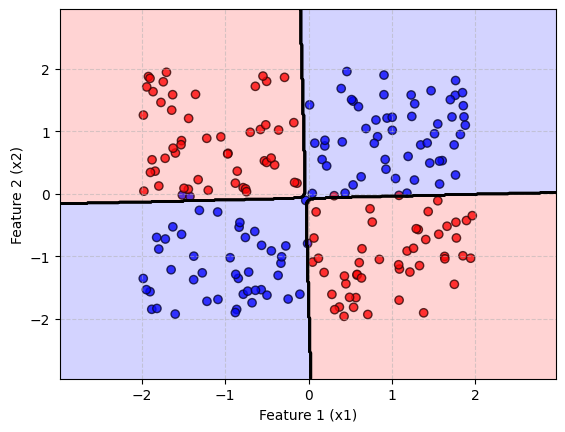

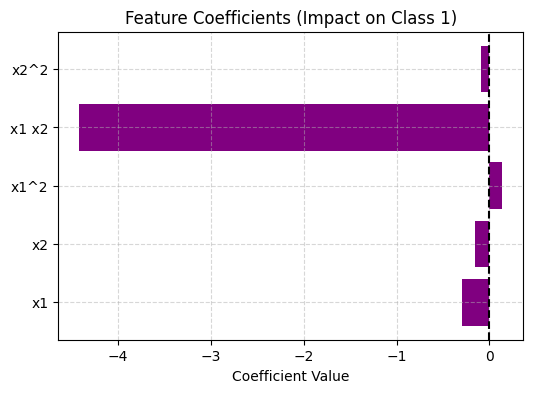

In [ ]:
# Let's construct a dataset representing an XOR-like relationship
np.random.seed(42)
X_train = np.random.uniform(-2, 2, size=(200, 2))
# Label is 1 if features have different signs (XOR), else 0
y_train = ( (X_train[:, 0] > 0) ^ (X_train[:, 1] > 0) ).astype(int)

# Calculate individual Pearson correlation coefficients with the target labels
corr_f1 = np.corrcoef(X_train[:, 0], y_train)[0, 1]
corr_f2 = np.corrcoef(X_train[:, 1], y_train)[0, 1]

print("=== Individual Feature Correlations ===")
print(f"Correlation of Feature 1 with Label: {corr_f1:.4f} (Nearly zero)")
print(f"Correlation of Feature 2 with Label: {corr_f2:.4f} (Nearly zero)")

# Combine the base features as a 2nd degree polynomila and add them to our features space
# 2D -> 5D features space
poly_transform = PolynomialFeatures(degree=2, include_bias=False)
model = make_pipeline(poly_transform, LogisticRegression(random_state=42))
model.fit(X_train, y_train)

# Plot the combined relationship (in the original 2D space)
plot_decision_boundary(model, X_train, y_train, show=False)

# Extract and visualize the individual coefficients from the polynomial pipeline
feature_names = poly_transform.get_feature_names_out(input_features=['x1', 'x2'])
poly_coefs = model.named_steps['logisticregression'].coef_[0]

# Visualize individual coefficients
plot_feature_coefficients(feature_names, poly_coefs)

---
## Part 3: Grid Search

The available training data can often be unsufficiently representative of the real distribution -> we want to avoid overfitting.

Subsampling the training data (into train-validation) splits can help us out to better choose model hyperparameters before actual training.


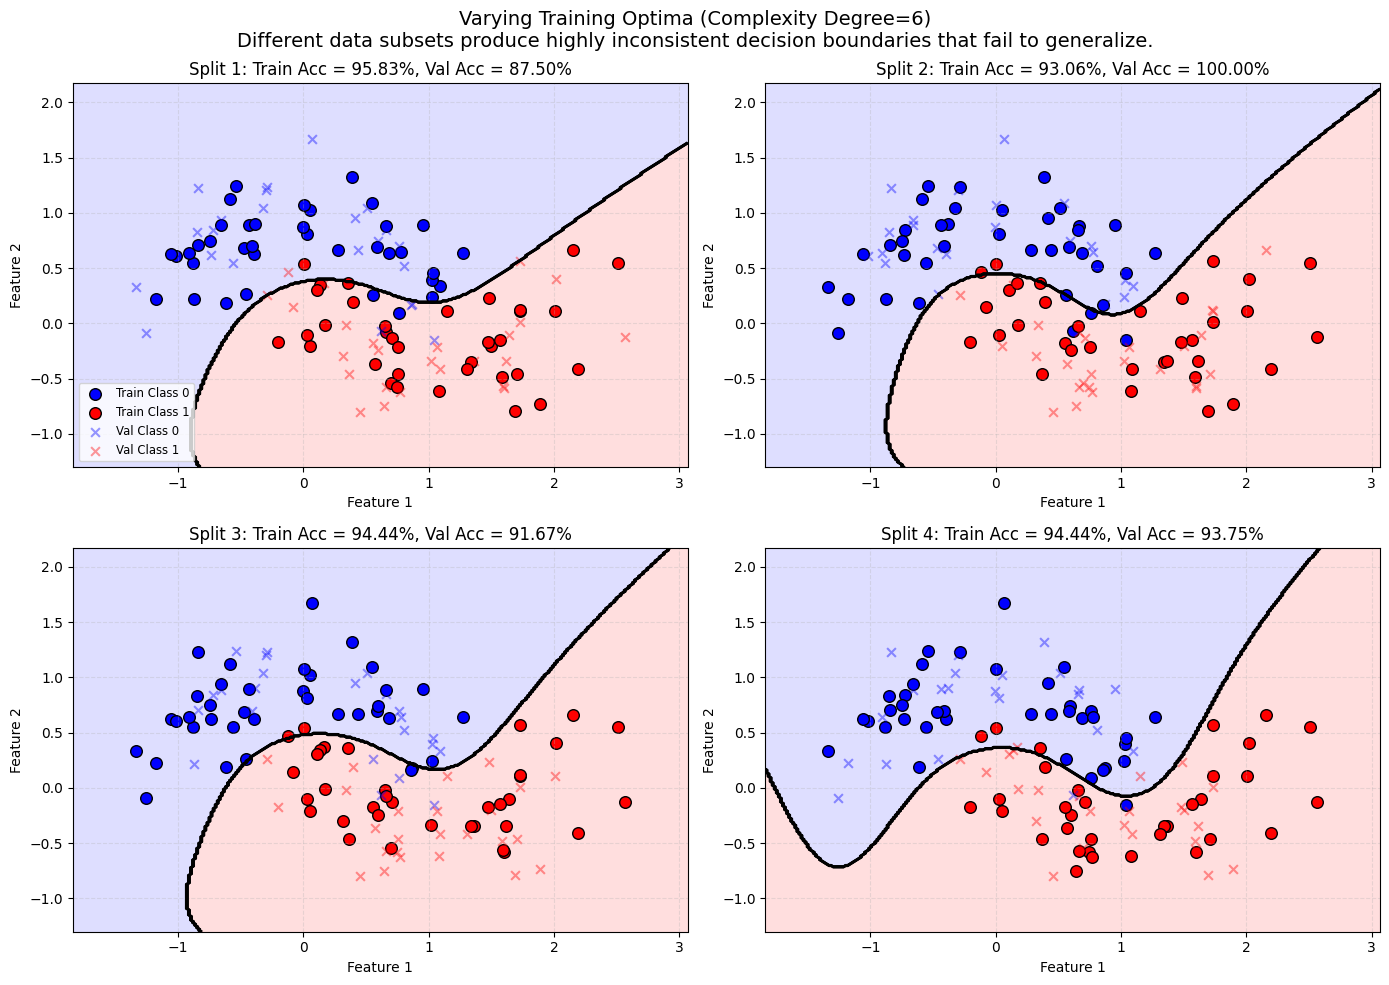

In [ ]:
# Generate a noisy 2D dataset
X_train, y_train = make_moons(n_samples=120, noise=0.25, random_state=42)

# Set up a grid of subplots to show how different random splits shift the decision boundary
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

# Define a high-capacity model (prone to high variance / overfitting)
poly_degree = 6
model_pipeline = make_pipeline(PolynomialFeatures(degree=poly_degree), LogisticRegression(C=1.0, solver='liblinear'))

# Generate 4 random training subsets (representing different splits/folds)
rs = ShuffleSplit(n_splits=4, train_size=0.6, random_state=10)

# Grid for plotting decision boundaries
a_min, a_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
b_min, b_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5
xa, xb = np.meshgrid(np.linspace(a_min, a_max, 300), np.linspace(b_min, b_max, 300))
grid = np.stack([xa.ravel(), xb.ravel()], axis=1)

for i, (train_index, test_index) in enumerate(rs.split(X_train)):
    X_train_s, y_train_s = X_train[train_index], y_train[train_index]
    X_val_s, y_val_s = X_train[test_index], y_train[test_index]

    # Fit the high-capacity model on this specific subset
    model_pipeline.fit(X_train_s, y_train_s)

    # Evaluate train and validation scores
    train_score = model_pipeline.score(X_train_s, y_train_s)
    val_score = model_pipeline.score(X_val_s, y_val_s)

    # Predict over the spatial grid
    Z = model_pipeline.predict(grid).reshape(xa.shape)

    # Plot on the corresponding subplot
    ax = axes[i]
    ax.contourf(xa, xb, Z, alpha=0.15, cmap='bwr')
    ax.contour(xa, xb, Z, colors='black', linewidths=1.5, linestyles='-')

    # Plot training points (large) and validation points (small/transparent)
    ax.scatter(X_train_s[y_train_s==0, 0], X_train_s[y_train_s==0, 1], color='blue', edgecolors='k', s=70, label='Train Class 0')
    ax.scatter(X_train_s[y_train_s==1, 0], X_train_s[y_train_s==1, 1], color='red', edgecolors='k', s=70, label='Train Class 1')
    ax.scatter(X_val_s[y_val_s==0, 0], X_val_s[y_val_s==0, 1], color='blue', marker='x', s=40, alpha=0.4, label='Val Class 0')
    ax.scatter(X_val_s[y_val_s==1, 0], X_val_s[y_val_s==1, 1], color='red', marker='x', s=40, alpha=0.4, label='Val Class 1')

    ax.set_title(f"Split {i+1}: Train Acc = {train_score:.2%}, Val Acc = {val_score:.2%}")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.grid(True, linestyle='--', alpha=0.3)
    if i == 0:
        ax.legend(loc='lower left', fontsize='small')

plt.suptitle(f"Varying Training Optima (Complexity Degree={poly_degree})\nDifferent data subsets produce highly inconsistent decision boundaries that fail to generalize.", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

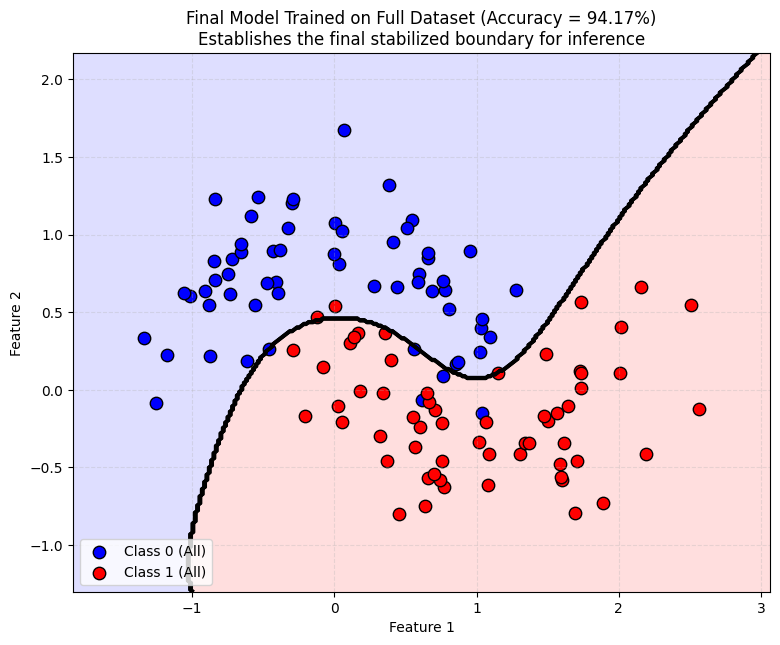

In [ ]:
def plot_final_decision_boundary(model, X, y, grid, xa, xb, train_score):
    """Plots the final stabilized decision boundary of the trained model over the data."""
    plt.figure(figsize=(9, 7))

    # Predict over the spatial grid
    Z_final = model.predict(grid).reshape(xa.shape)

    # Plot decision regions and boundary
    plt.contourf(xa, xb, Z_final, alpha=0.15, cmap='bwr')
    plt.contour(xa, xb, Z_final, colors='black', linewidths=2.0, linestyles='-')

    # Plot all dataset points
    plt.scatter(X[y==0, 0], X[y==0, 1], color='blue', edgecolors='k', s=80, label='Class 0 (All)')
    plt.scatter(X[y==1, 0], X[y==1, 1], color='red', edgecolors='k', s=80, label='Class 1 (All)')

    plt.title(f"Final Model Trained on Full Dataset (Accuracy = {train_score:.2%})\nEstablishes the final stabilized boundary for inference", fontsize=12)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.legend(loc='lower left')
    plt.show()

# Train the final model on the full dataset (all 120 samples)
model = make_pipeline(PolynomialFeatures(degree=6), LogisticRegression(C=1.0, solver='liblinear'))
model.fit(X_train, y_train)
full_train_score = model.score(X_train, y_train)

# Visualize the decision boundary of the final model using our isolated function
plot_final_decision_boundary(model, X_train, y_train, grid, xa, xb, full_train_score)